<a href="https://colab.research.google.com/github/kaz3107/IS4487/blob/main/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load cleaned Airbnb data
df = pd.read_csv('/content/cleaned_airbnb_data_6.csv')

# Check the data
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1188641052152277018,https://www.airbnb.com/rooms/1188641052152277018,20260615212226,2026-06-16,city scrape,Spacious unit at heart of SEA,"Located in the heart of Seattle, This is a stu...",https://a0.muscache.com/pictures/miso/Hosting-...,32542619,https://www.airbnb.com/users/show/32542619,...,NaN,NaN,NaN,NaN,NaN,4,4,0,0,NaN
1,849077848951991421,https://www.airbnb.com/rooms/849077848951991421,20260615212226,2026-06-16,city scrape,"Blueground | Central District, gym & bbq, nr d...",Feel at home wherever you choose to live with ...,https://a0.muscache.com/pictures/prohost-api/H...,107434423,https://www.airbnb.com/users/show/107434423,...,NaN,NaN,NaN,NaN,NaN,239,239,0,0,NaN
2,599205596133828323,https://www.airbnb.com/rooms/599205596133828323,20260615212226,2026-06-16,city scrape,purple room,simple room facing front yard in centrally lo...,https://a0.muscache.com/pictures/miso/Hosting-...,48441443,https://www.airbnb.com/users/show/48441443,...,5.00,5.00,5.00,NaN,NaN,5,0,5,0,0.06
3,846763,https://www.airbnb.com/rooms/846763,20260615212226,2026-06-16,city scrape,Right at Home in Ravenna,"Our home is a lovely peaceful place, and we wi...",https://a0.muscache.com/pictures/62990267/b8fe...,4421734,https://www.airbnb.com/users/show/4421734,...,4.89,4.89,4.90,NaN,NaN,1,0,1,0,0.51
4,1512026480622905433,https://www.airbnb.com/rooms/1512026480622905433,20260615212226,2026-06-16,city scrape,"3 Min Walk to Capitol Hill Station, Brand New ...",Brand new 3BR/3BA townhome in the heart of Cap...,https://a0.muscache.com/pictures/hosting/Hosti...,44486963,https://www.airbnb.com/users/show/44486963,...,4.94,4.89,4.94,STR-OPLI-25-004798,NaN,1,1,0,0,4.30


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

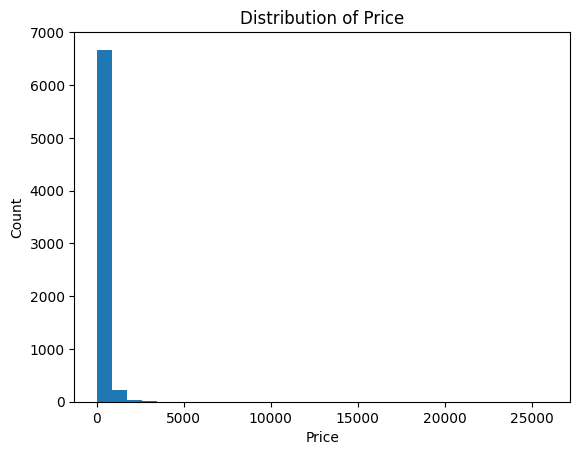

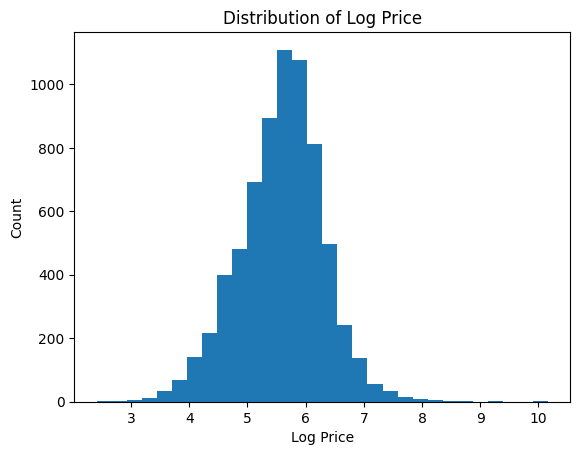

In [3]:
# Histogram of price
plt.hist(df['price'].dropna(), bins=30)
plt.title("Distribution of Price")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

# Log transform price
df['log_price'] = np.log1p(df['price'])

# Histogram after transformation
plt.hist(df['log_price'].dropna(), bins=30)
plt.title("Distribution of Log Price")
plt.xlabel("Log Price")
plt.ylabel("Count")
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined the price column because the original histogram showed that the data was highly skewed.

2. I used a log transformation because there were a few very high prices compared to most of the listings.

3. I noticed that the transformed distribution is less skewed and easier to see. I think this makes the price data easier to compare and understand for analysis.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [4]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale
minmax = MinMaxScaler()
df['price_scaled'] = minmax.fit_transform(df[['price']])

# Z-score scale
standard = StandardScaler()
df['minimum_nights_scaled'] = standard.fit_transform(df[['minimum_nights']])

df[['price', 'price_scaled', 'minimum_nights', 'minimum_nights_scaled']].describe()

,price,price_scaled,minimum_nights,minimum_nights_scaled
count,6943.000000,6943.000000,7763.000000,7.763000e+03
mean,349.719676,0.013106,9.210099,-8.237646e-18
std,465.813269,0.017981,18.850462,1.000064e+00
min,10.180000,0.000000,1.000000,-4.355664e-01
25%,171.500000,0.006227,1.000000,-4.355664e-01
50%,281.000000,0.010454,2.000000,-3.825139e-01
75%,422.240000,0.015906,6.000000,-1.703038e-01
max,25916.670000,1.000000,730.000000,3.823972e+01



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I scaled the price column using Min-Max scaling and the minimum_nights column using Z-score standardization.

2. I think the scaled values could be more useful when comparing variables with very different ranges or when using them in a model.

3. I think Airbnb analysts could benefit from this transformation because it makes variables like price and minimum nights easier to compare and use together in analysis or modeling.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [5]:
# Group number of reviews into 3 categories
df['review_group'] = pd.qcut(df['number_of_reviews'], q=3, labels=['Low', 'Medium', 'High'])

df['review_group'].value_counts()

,count
review_group,
Low,2638
High,2581
Medium,2550


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped the number_of_reviews column into three categories: Low, Medium, and High.

2. I think the grouped view makes it easier to compare listings by general review activity instead of looking at many different review counts.

3. I think this could help Airbnb marketing teams identify listings with different levels of review activity and use those groups for analysis or marketing decisions.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [6]:
# Create price per guest
df['price_per_guest'] = df['price'] / df['accommodates'].replace(0, np.nan)

# Create long-term stay flag
df['long_term_stay'] = (df['minimum_nights'] > 30).astype(int)

# Check new columns
df[['price', 'accommodates', 'price_per_guest',
    'minimum_nights', 'long_term_stay']].head()

,price,accommodates,price_per_guest,minimum_nights,long_term_stay
0,122.32,3,40.773333,30.0,0
1,NaN,4,NaN,30.0,0
2,68.30,2,34.150000,30.0,0
3,66.58,1,66.580000,30.0,0
4,540.00,8,67.500000,1.0,0


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created price_per_guest to estimate the price per guest and long_term_stay to identify listings that require more than 30 minimum nights.

2. I think hosts or Airbnb managers could use these variables to better understand pricing and identify listings that are more focused on longer stays.

3. I think these variables could help compare the value of different listings and make decisions about pricing or which types of guests to target.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [7]:
# One-hot encode room type
room_type_encoded = pd.get_dummies(df['room_type'], prefix='room')

# Add new columns to the dataframe
df = pd.concat([df, room_type_encoded], axis=1)

# Check new columns
room_type_encoded.head()

,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,True,False,False,False
1,True,False,False,False
2,False,False,True,False
3,False,False,True,False
4,True,False,False,False


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded the room_type column because it contains categories that could be useful for comparing different types of Airbnb listings.
2. I used one-hot encoding because the room types are nominal categories and do not have a natural order.
3. I think this transformation could help a pricing model or dashboard compare prices and booking patterns across different room types.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [8]:
# Export cleaned data
df.to_csv('cleaned_airbnb_data_7.csv', index=False)

## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. I think the log transformation of price was the most interesting because I could clearly see how it made the highly skewed price distribution easier to understand.
2. I think the price_per_guest variable could be especially useful to hosts or analysts because it makes it easier to compare the value of listings with different guest capacities.
3. If I were building a dashboard, I would use this data to compare prices, room types, and review activity so users could better understand different types of listings.
4. I think this assignment relates to my learning outcomes because I practiced reading and changing Python code to transform data and created new variables that could help answer business questions.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [9]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_07_data_transformation.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_y